# RAG Based Profile Matching — experiments and analysis

This notebook runs real HuggingFace embeddings against ChromaDB. The 32 resumes and seven JDs are explicitly synthetic. No benchmark values are invented. Run all cells after installing `requirements-rag.txt`; the first run downloads the embedding model.

**Questions:** How does semantic/keyword weighting affect candidate retrieval? How does chunk size affect accuracy and index size? Which must-have filters change the results?

In [1]:
from pathlib import Path
import os, sys, json, time
root = Path.cwd()
if root.name == 'notebooks': root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))
from resume_rag import ResumeRAG
from job_matcher import JobMatcher
from evaluate import evaluate
queries = json.loads(Path('data/relevance.json').read_text())
rag = ResumeRAG()
start = time.perf_counter()
index_summary = rag.index_directory()
print(index_summary)
print('Index time (excluding model loading):', round(time.perf_counter()-start, 3), 'seconds')

/Users/akashkawale/Downloads/llm-file-assistant/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1018 23:18:04.794000 40968 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|███████████████| 103/103 [00:00<00:00, 20219.66it/s]


{'resumes': 32, 'chunks': 224, 'model': 'sentence-transformers/all-MiniLM-L6-v2'}
Index time (excluding model loading): 0.332 seconds


## Inspect metadata and section boundaries
Experience is extracted conservatively from explicitly declared professional experience. Unknown totals are stored as -1, surfaced as null. Skill-specific years are separate from total years. The fixed skill vocabulary and section heading rules are transparent, limited heuristics.

In [2]:
from resume_rag import extract_metadata, chunk_document
text = Path('data/resumes/candidate_25.txt').read_text()
print(json.dumps(extract_metadata(text, 'data/resumes/candidate_25.txt'), indent=2))
print([(c['section'], len(c['text'].split())) for c in chunk_document(text)])

{
  "candidate_name": "Om Bhat",
  "resume_path": "data/resumes/candidate_25.txt",
  "skills_json": "[\"AWS\", \"DRF\", \"Django\", \"Docker\", \"Git\", \"PostgreSQL\", \"Python\"]",
  "experience_years": 8.0,
  "skill_years_json": "{\"Python\": 3.0, \"Django\": 7.0, \"DRF\": 6.0, \"PostgreSQL\": 8.0, \"Docker\": 7.0, \"AWS\": 8.0, \"Git\": 6.0}",
  "education": "B.E. Electronics Engineering, Example Institute, 2018."
}
[('Profile', 11), ('Summary', 16), ('Skills', 8), ('Experience', 52), ('Education', 7), ('Projects', 13), ('Certifications', 9)]


## Experiment 1: semantic vs hybrid ranking
Hold filters and dataset constant. Weight 1.0 is semantic-only ranking **after the same hard filters**. The hybrid score is `100 * (weight * max_chunk_cosine + (1-weight) * JD_skill_coverage)`, with cosine clipped to [0,1]. This is a heuristic score, not a probability.

Labels are authored from synthetic role groups and declared seniority, not generated from retrieved rankings. Precision@10 always divides by 10, even when filters leave fewer candidates; inspect recall and nDCG alongside precision. This benchmark has only 1–4 relevant resumes per query, so perfect Precision@10 is impossible.

In [3]:
matcher = JobMatcher(rag)
results = [evaluate(matcher, queries, weight=w, repeats=3) for w in [1.0, 0.7, 0.4]]
for result in results:
    print(result['semantic_weight'], result['macro_average'])
Path('outputs').mkdir(exist_ok=True)
Path('outputs/rag_notebook_metrics.json').write_text(json.dumps(results, indent=2))

1.0 {'precision_at_10': 0.35714285714285715, 'recall_at_10': 1.0, 'ndcg_at_10': 1.0, 'reciprocal_rank': 1.0, 'median_latency_ms': 11.44}
0.7 {'precision_at_10': 0.35714285714285715, 'recall_at_10': 1.0, 'ndcg_at_10': 1.0, 'reciprocal_rank': 1.0, 'median_latency_ms': 10.335714285714285}
0.4 {'precision_at_10': 0.35714285714285715, 'recall_at_10': 1.0, 'ndcg_at_10': 1.0, 'reciprocal_rank': 1.0, 'median_latency_ms': 10.262857142857143}


6666

Matplotlib is building the font cache; this may take a moment.


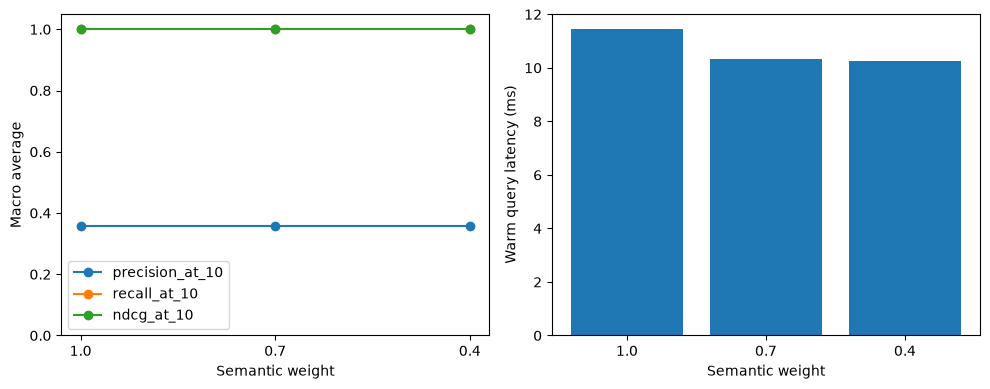

In [4]:
import matplotlib.pyplot as plt
labels = [str(r['semantic_weight']) for r in results]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for metric in ['precision_at_10', 'recall_at_10', 'ndcg_at_10']:
    axes[0].plot(labels, [r['macro_average'][metric] for r in results], marker='o', label=metric)
axes[0].set(xlabel='Semantic weight', ylabel='Macro average', ylim=(0,1.05))
axes[0].legend()
axes[1].bar(labels,[r['macro_average']['median_latency_ms'] for r in results])
axes[1].set(xlabel='Semantic weight',ylabel='Warm query latency (ms)')
plt.tight_layout()
plt.show()

## Experiment 2: section chunk size
Use separate databases so the main index remains intact. The same embedding model is reused. Short templates may fit within every chunk size, so a flat result is valid; inspect chunk counts before drawing conclusions.

In [5]:
chunk_results = []
for size in [80, 140, 200]:
    trial = ResumeRAG(db_path=f'chroma_db_chunk_{size}', embedder=rag.embedder)
    summary = trial.index_directory(max_words=size, overlap=20)
    evaluation = evaluate(JobMatcher(trial), queries, repeats=3)
    chunk_results.append({'max_words':size, 'chunks':summary['chunks'], **evaluation['macro_average']})
chunk_results

[{'max_words': 80,
  'chunks': 224,
  'precision_at_10': 0.35714285714285715,
  'recall_at_10': 1.0,
  'ndcg_at_10': 1.0,
  'reciprocal_rank': 1.0,
  'median_latency_ms': 10.044285714285714},
 {'max_words': 140,
  'chunks': 224,
  'precision_at_10': 0.35714285714285715,
  'recall_at_10': 1.0,
  'ndcg_at_10': 1.0,
  'reciprocal_rank': 1.0,
  'median_latency_ms': 10.252857142857144},
 {'max_words': 200,
  'chunks': 224,
  'precision_at_10': 0.35714285714285715,
  'recall_at_10': 1.0,
  'ndcg_at_10': 1.0,
  'reciprocal_rank': 1.0,
  'median_latency_ms': 10.08}]

## Filter demonstration and error analysis
Candidate 25 has eight total years but only three Python years. Candidate 17 has five Python years. A five-year Python requirement should include candidate 17 and exclude candidate 25. Read the cited sections to verify each result.

In [6]:
result = matcher.match(Path('data/jobs/job_07.txt').read_text())
print(json.dumps(result, indent=2))
paths = [m['resume_path'] for m in result['top_matches']]
assert 'data/resumes/candidate_25.txt' not in paths
assert 'data/resumes/candidate_17.txt' in paths
for query in queries:
    matches = matcher.match(Path(query['path']).read_text())['top_matches']
    returned = {m['resume_path'] for m in matches}
    relevant = set(query['relevant'])
    print(query['id'], 'missed:', sorted(relevant-returned), 'extra:', sorted(returned-relevant))

{
  "job_description": "Senior Python Backend Developer\nBuild Python Django APIs using PostgreSQL. Requires 5+ years Python. Must-have: Python, Django\n",
  "top_matches": [
    {
      "candidate_name": "Vivaan Jain",
      "resume_path": "data/resumes/candidate_17.txt",
      "match_score": 78.29,
      "matched_skills": [
        "Django",
        "PostgreSQL",
        "Python"
      ],
      "relevant_excerpts": [
        "Experience: Total professional experience: 5 years Python Backend Developer at Fictional Example Organization 17. Built REST APIs with authentication, relational models, database indexes, and asynchronous task queues. Explicit professional skill experience: Python: 5 years Django: 4 years DRF: 3 years PostgreSQL: 5 years Docker: 4 years Git: 3 years",
        "Skills: Python, Django, DRF, PostgreSQL, Docker, Git",
        "Summary: Python Backend Developer. 5 years total professional experience. Interested in reliable software and collaborative delivery."
      

## Interpretation and limitations

- Compare measured recall/nDCG and latency above before selecting a weight; do not assume hybrid always wins. The default 0.7 is an initial choice.
- Template overlap and skill-based hard filters make this dataset easier than real resumes. Report the synthetic provenance and avoid generalizing these scores.
- The weighting experiment compares ranking under identical filters; it does not measure whether automatic JD requirement extraction is correct.
- Search reads all indexed chunks for candidate aggregation. This is appropriate for 32 resumes but requires candidate-pool retrieval, pagination, and keyword indexing at larger scale.
- Section recognition and metadata extraction are rule-based. Unsupported date ranges, negation ("no Python experience"), complex layouts, and unfamiliar skill aliases need stronger extraction and reviewed labels.
- Scanned PDFs require OCR. Long JDs and unusually dense chunks may be truncated by the embedding model. Index rebuilds are not transactional; do not query concurrently during rebuild.
- A stronger follow-up is a separately labelled, consented dataset with paraphrased JDs, distractor skills, and independently reviewed relevance judgements. Keep tuning and final evaluation splits separate.
- This is retrieval plus evidence-grounded template reasoning. It does not call a generative LLM for final reasoning; add one only if the course explicitly requires that beyond the supplied brief.